# Symbolic Regression using Sparse Identification of Nonlinear Dynamics (SINDy)

In [3]:
# Load libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.integrate import solve_ivp

# Clone the repository to be able to access custom utilities
# for this tutorial. This is only needed if you are running 
# this notebook on Google Colab.
import os
IN_COLAB = 'COLAB_RELEASE_TAG' in os.environ
if IN_COLAB:
    if not os.path.exists('<repo>'):
        !git clone https://github.com/<username>/<repo>.git
    %pip install pysindy
    %cd <repo>

# Load custom utilities
from utils import LV_PALETTE, generate_lv_data

# Introduction to Model Discovery and Symbolic Regression

### What is model discovery?

xxx
- Goal: learn the underlying dynamics of a system from data
- Taditionally done through a loop in which a model is proposed, tested against data, and refined until it fits the data well enough. This is a time-consuming process that requires a lot of domain knowledge and expertise.
- Example: My PARPi model.

Side note: the process of "discarding" a model is in itself a key part of the scientific method (potentially arguable THE key part). Scientists can never prove something. They can only fail to disprove it. A model that fails tells us a key assumption of our model is wrong or missing!

![alt text](figures/figures.002.png)

### Symbolic Regression
However, this same process is also **quite time-consuming** and requires a lot of domain knowledge and expertise. With that domain "knowledge" also comes **bias**. We may only propose models that we are familiar with and have seen before. 

Symbolic regression seeks to overcome these limitations. It is a family of methods which seek to automate the discovery process in order to make it more efficient and less prone to human bias.
, in a way that tries to be more agnostic about which processes are thought to be driving a system and how these are functionally represented.

Broadly, there are three main approaches to symbolic regression:
1. **Genetic programming (GP):** a method that uses evolutionary algorithms to evolve mathematical expressions that fit the data. For example, PySR is a Python library that implements GP for symbolic regression.
2. **Sparse Identification of Nonlinear Dynamics (SINDy):** a method that uses sparse regression on a candidate library of terms to identify the right-hand side of the differential equation model. This is what we will cover today.
3. **Symbolic Transformers:** transformer-based embedding models trained to map ODE trajectories to equations. See [Farbod's tutorial](https://colab.research.google.com/github/farbodf91/ix-verifier-guided-discovery/blob/main/01_IX_symbolic_discovery_tutorial.ipynb) for more details 

## Sparse Identification of Nonlinear Dynamics (SINDy)


Sparse Identification of Nonlinear Dynamics (SINDy) is a method for dynamics discovery which was first proposed by Brunton et al in 2016 (Brunton et al 2016. PNAS). It's greatest strengths is that it is very portable and adpat to new applications, computationally inexpensive [xxx]. Since its inception it has rapidly been adopted in a number of fields ranging from xxx to cancer research [xxx] and many additional extensions have been developed (e.g. Bayesian SINDy [xxx], Ensemble SINDy [xxx], SINDy for rational functions [xxx]; we will discuss some below).

### The principle intuition behind SINDy
The key observation underlying SINDy is that the right-hand-sides of many dynamical systems are linear in their coefficients. This means that while the RHS may involve terms which are nonlinear in the state variables, such as $x^2$ or $x_1 x_2$, these nonlinear terms combine in a linear way to give the overall dynamics, where the coefficients/parameters are the weights in this weighted sum. For example, take the Lorenz equations. We can re-write them as follows:

\begin{equation}
    \begin{bmatrix} \dot{x} \\ \dot{y} \\ \dot{z} \end{bmatrix}
    =
    \begin{bmatrix}
        \sigma(y-x) \\
        x(\rho-z)-y \\
        xy - \beta z
    \end{bmatrix}
    =
    \begin{bmatrix}
        (-\sigma) x + \sigma y \\
        \rho x + (-1) y + (-1) xz \\
        (-\beta) z + xy
    \end{bmatrix}
    =
    \begin{bmatrix}
        -\sigma & \sigma & 0      & 0  & 0 \\
        \rho    & -1     & 0      & -1 & 0 \\
        0       & 0      & -\beta & 0  & 1
    \end{bmatrix}
    \begin{bmatrix} x \\ y \\ z \\ xz \\ xy \end{bmatrix}
    =
    \boldsymbol{\Xi}\,\boldsymbol{\theta}(\mathbf{x}),
\end{equation}

where $\boldsymbol{\theta}(\mathbf{x})$ is a vector of state-variable terms, and the *coefficient matrix* $\boldsymbol{\Xi}$ specifies how those terms are combined to form each equation.

This observation is important because it allows us to recast the problem of finding the governing equations as a linear regression problem. Suppose we propose a collection of candidate functional terms that might appear on the RHS of the dynamical system we wish to identify, and collate them into a *function library*:

\begin{equation}
    \boldsymbol{\Theta}(\mathbf{x}) = \begin{bmatrix} 1 & x & y & z & xy & xz & yz & x^2 & \cdots \end{bmatrix}.
\end{equation}

Crucially, we can calculate each term in $\boldsymbol{\Theta}(\mathbf{x})$ directly from our observations of the  system. 

The problem of discovering the governing equations then reduces to finding the coefficient matrix $\boldsymbol{\Xi}$ such that

\begin{equation}
    \dot{\mathbf{x}}^\top = \boldsymbol{\Theta}(\mathbf{x})\,\boldsymbol{\Xi}.
\end{equation}

In other words, we are solving a linear regression problem in which we seek to find the matrix $\boldsymbol{\Xi}$ such that $\mathbf{Y} = \mathbf{X}\boldsymbol{\Xi}$, where $\mathbf{Y}$ contains the system's derivatives and $\mathbf{X}$ the evaluated library terms (our "explanatory variables").

### The SINDy algorithm

Let us assume we are trying to learn the governing equations of a system with $n$ state variables, $\mathbf{x} = [x_1, x_2, \ldots, x_n]^\top$. To do so, we have collected $m$ observations of the system at different points in time, which we will denote by $\mathbf{\hat{x}}_i = \mathbf{\hat{x}}(t_i) = [x_1(t_i), x_2(t_i), \ldots, x_n(t_i)]^\top$, for $i = 1, 2, \ldots, m$. We can assemble these observations into a data matrix 

\begin{equation}
    \mathbf{\hat{X}} =
    \;=\;
    \begin{bmatrix}
        \hat{x}_1(t_1) & \hat{x}_2(t_1) & \cdots & \hat{x}_n(t_1) \\
        \hat{x}_1(t_2) & \hat{x}_2(t_2) & \cdots & \hat{x}_n(t_2) \\
        \vdots    & \vdots    & \ddots & \vdots \\
        \hat{x}_1(t_m) & \hat{x}_2(t_m) & \cdots & \hat{x}_n(t_m)
    \end{bmatrix}.
\end{equation}

Note, that here and throughout, $x_i(t_j)$ denotes the value of the $i$-th state variable at time $t_j$ (the ground truth), and $\hat{x}_i(t_j)$ denotes our observed value of that state variable at that time. Ideally, of course, the two are the same, but in practice measurement noise and other sources of error typically mean that they are not.

Applying SINDy to this data proceeds in five main steps:

#### Step 1: Obtain observations of the time derivatives of the state variables
In the first step, we use the data matrx to estimate the time derivatives of the state variables, $\dot{\mathbf{x}} = [\dot{x}_1, \dot{x}_2, \ldots, \dot{x}_n]^\top$, at each observation time. We can then assemble these estimated derivatives into a second matrix with the observed derivatives,

\begin{equation}
    \dot{\mathbf{\hat{X}}} =
    \begin{bmatrix}
        \dot{\hat{x}}_1(t_1) & \dot{\hat{x}}_2(t_1) & \cdots & \dot{\hat{x}}_n(t_1) \\
        \dot{\hat{x}}_1(t_2) & \dot{\hat{x}}_2(t_2) & \cdots & \dot{\hat{x}}_n(t_2) \\
        \vdots          & \vdots          & \ddots & \vdots \\
        \dot{\hat{x}}_1(t_m) & \dot{\hat{x}}_2(t_m) & \cdots & \dot{\hat{x}}_n(t_m)
    \end{bmatrix},
\end{equation}

where $\dot{x_i}(t)$ denotes the time derivative of $x_i$ evaluated at time $t$, $\frac{dx_i}{dt}(t)$, and $\dot{\hat{x}}_i(t)$ denotes our estimate of that derivative at that time. 

To obtain these estimates, we typically use finite difference methods. Crucially, as for any statistical method the output of SINDy is only as good as the input data. If the derivative estimates are poor, the resulting model will be poor as well. In this particular context, derivative estimates are particularly sensitive to noise in the data, and so it is important to use a method that is robust to noise, and potentially apply appropriate smoothing or filtering to the data before estimating derivatives.

#### Step 2: Propose a library of candidate functions
In the second step, we propose a library of candidate functions that might appear on the right-hand side of the governing equations. This library is typically constructed from a set of basis functions, such as polynomials, trigonometric functions, or other functions that are thought to be relevant to the system. The library is then evaluated at each observation time, and the resulting values are assembled into a third matrix, which we call the *library matrix*, 
\begin{equation}
    \mathbf{\Theta}(\mathbf{\hat{X}}) =
    \begin{bmatrix}
        \theta_1(\mathbf{\hat{x}}(t_1)) & \theta_2(\mathbf{\hat{x}}(t_1)) & \cdots & \theta_p(\mathbf{\hat{x}}(t_1)) \\
        \theta_1(\mathbf{\hat{x}}(t_2)) & \theta_2(\mathbf{\hat{x}}(t_2)) & \cdots & \theta_p(\mathbf{\hat{x}}(t_2)) \\
        \vdots          & \vdots          & \ddots & \vdots \\
        \theta_1(\mathbf{\hat{x}}(t_m)) & \theta_2(\mathbf{\hat{x}}(t_m)) & \cdots & \theta_p(\mathbf{\hat{x}}(t_m))
    \end{bmatrix},
\end{equation}

where $\theta_j(\mathbf{x})$ denotes the $j$-th candidate function evaluated at the state vector $\mathbf{x}$, and $p$ is the total number of candidate functions in the library.

For example, if we propose a library of polynomial functions up to degree 2, the library matrix would be
\begin{equation}
    \mathbf{\Theta}(\mathbf{\hat{X}}) =
    \begin{bmatrix}
        1 & \hat{x}_1(t_1) & \hat{x}_2(t_1) & \cdots & \hat{x}_n(t_1) & \hat{x}_1(t_1)^2 & \hat{x}_1(t_1)\hat{x}_2(t_1) & \cdots & \hat{x}_n(t_1)^2 \\
        1 & \hat{x}_1(t_2) & \hat{x}_2(t_2) & \cdots & \hat{x}_n(t_2) & \hat{x}_1(t_2)^2 & \hat{x}_1(t_2)\hat{x}_2(t_2) & \cdots & \hat{x}_n(t_2)^2 \\
        \vdots          & \vdots          & \vdots          & \ddots & \vdots          & \vdots          & \vdots          & \ddots & \vdots          \\
        1 & \hat{x}_1(t_m) & \hat{x}_2(t_m) & \cdots & \hat{x}_n(t_m) & \hat{x}_1(t_m)^2 & \hat{x}_1(t_m)\hat{x}_2(t_m) & \cdots & \hat{x}_n(t_m)^2
    \end{bmatrix}.
\end{equation}

Choosing the right library of candidate functions is crucial to the success of SINDy. If the true governing equations contain terms that are not included in the library, SINDy will not be able to identify them. Conversely, if the library contains too many irrelevant terms, SINDy may overfit the data and produce a model that does not generalize well to new data. Importantly, what constitutes a "success" and a "good" library also depends on what the goal of the analysis is. Is our goal to build a highly accurate model, and perhaps one that runs fast and efficiently? In that case we might not care about whether the true terms are all contained and instead might satisfy efficient approximations. Conversely, if we have spefic library terms in mind - for example, from prior knowledge or subject expertise - and we want to know what the best approximation of the system is using just those terms, we might choose a smaller, curated library, at the expense of model accuracy.

#### Step 3: Solve the sparse regression problem
We are now ready to perform inference. To do so, we solve the following multi-variate, multiple, linear regression problem
\begin{equation}
    \dot{\mathbf{\hat{X}}} = \mathbf{\Theta}(\mathbf{\hat{X}})\,\boldsymbol{\Xi},
\end{equation}
where $\boldsymbol{\Xi}$ is the coefficient matrix we wish to estimate, and has the form
\begin{equation}
    \boldsymbol{\Xi} =
    \begin{bmatrix}
        \xi_{11} & \xi_{12} & \cdots & \xi_{1n} \\
        \xi_{21} & \xi_{22} & \cdots & \xi_{2n} \\
        \vdots   & \vdots   & \ddots & \vdots   \\
        \xi_{p1} & \xi_{p2} & \cdots & \xi_{pn}
    \end{bmatrix},
\end{equation}
where $\xi_{ij}$ is the coefficient of the $i$-th library term in the equation for the $j$-th state variable. This means that the estimated governing equation for $j$-th state variable is given by
\begin{equation}
    \dot{x}_j = \xi_{1j} \theta_1(\mathbf{x}) + \xi_{2j} \theta_2(\mathbf{x}) + \cdots + \xi_{pj} \theta_p(\mathbf{x}).
\end{equation}

To solve this problem, we can use any standard linear regression method, including standard ordinary least squares (OLS). 

#### Step 4: Encourage sparsity in the coefficient matrix
While Step 3 will give us a solution for the coefficient matrix $\boldsymbol{\Xi}$, it is likely to be dense (i.e., many of the coefficients will be non-zero). However, we expect that only a few of the candidate functions will be relevant to the governing equations, and so we want to encourage sparsity in the coefficient matrix.

There are different ways to do so, including using a sparse regression method, such as LASSO or sequential thresholding. These methods add a penalty term to the regression objective function that encourages small coefficients to be set to zero, effectively performing feature selection and yielding a sparse solution. Here we will use sequential thresholding, which is a simple and effective method for encouraging sparsity in the coefficient matrix, and is the method Brunton et al used in their original work [xxx]. 

The idea of the Sequentially Thresholded Least Squares (STLS) algorithm is to iteratively fit the regression model, and at each iteration, set any coefficients that are below a certain threshold, $\lambda$, to zero. This process is repeated until convergence, yielding a sparse solution for the coefficient matrix.

#### Step 5: Model validation and selection
Finally - and crucially - once we have built a model, the true art and science of modelling begins. We assess the model's performance on tasks such as prediction, interpretation, and generalization - depending on our use case. We may compare the model's performance against alternative models, and select the best one based on some criteria, such as AIC, BIC, or cross-validation error. Importantly, depending on whether the goal is to build a highly accurate model, or to identify the true governing equations, the goal here the key information is in either the best fitting model - or in the models which we discarded. xxx

### Example: SINDy on the Lotka-Volterra equations

To illustrate how SINDy works in practice, we will apply it to some simulated data where we know the underlying governing equations. In this way, we can assess how well SINDy is able to recover the true governing equations from the data.

My research focuses on the ecology between different populations of cancer cells. So, I have chosen to illustrate the use of SINDy on the Lotka-Volterra model of competition. This model is one of the most well-known models in ecology and describes the population dynamics between two species in an ecosystem. It has been used extensively to understand under what conditions species can co-exist and what determines the stability of ecosystems. 

Let $x(t)$ denote the density of Species X, and $y(t)$ denote the density of Species Y. The Lotka-Volterra equations are given by
\begin{align}
    \dot{x} &= \underbrace{r_x x}_{\text{growth}} - \underbrace{c_{xx} x x}_{\text{intra-specific competition between members of X}} - \underbrace{c_{yx} x y}_{\text{inter-specific competition between X and Y}} \\
    \dot{y} &= \underbrace{r_y y}_{\text{growth}} - \underbrace{c_{yy} y y}_{\text{intra-specific competition between members of Y}} - \underbrace{c_{xy} y x}_{\text{inter-specific competition between Y and X}}
\end{align}

where $r_x$ and $r_y$ are the intrinsic growth rates of Species X and Y, respectively, and $c_{xx}$, $c_{yx}$, etc are the competition coefficients that quantify the effect of interactions on growth (e.g. the effect of Species Y on Species X is given by $c_{yx}$). We assume that we start with a total initial population of size $n_0 = x(0) + y(0)$, where the initial fraction of Species Y is given by $f_y = y(0)/n_0$.

#### 1) The Data
For this example, we will use the following parameter values:
- $r_x = 0.1$
- $r_y = 0.08$
- $c_{xx} = r_x$
- $c_{yy} = r_y$
- $c_{yx} = 0.05$
- $c_{xy} = 0.02$
- $n_0 = 0.1$
- $f_y = 0.5$

and we will assume that we have collected data on each population once a day for 100 days, and that for simplicity we have no measurement noise. 

In [3]:
# Define the parameters of the Lotka-Volterra model
params_dict = {
    "r_x": 0.1,  # growth rate of species X
    "r_y": 0.08,  # growth rate of species Y
    "c_xx": 0.1,  # intra-specific competition coefficient for species X
    "c_yy": 0.08,  # intra-specific competition coefficient for species Y
    "c_yx": 0.05,  # inter-specific competition coefficient from species Y to X
    "c_xy": 0.02,  # inter-specific competition coefficient from species X to Y
}
ic_dict = {
    "n0": 0.1,  # total initial population size
    "f_y": 0.5,  # initial fraction of species Y
}
duration_of_experiment = 100  # duration of observation in time units
sampling_interval = 1 # interval at which we are collecting observations

# Simulate the Lotka-Volterra dynamics and generate observations. To facilitate this, I have written 
# a function that will do this for us. It takes in the parameters and details of the experiment we 
# want to run and returns a pandas DataFrame containing the observations of the two species over time.
observations_df = generate_lv_data(params_dict=params_dict, ic_dict=ic_dict,
                 sampling_interval=sampling_interval, t_end=duration_of_experiment)

# Inspect observations
observations_df.head(10)

,t,x,y
0,0,0.050000,0.050000
1,1,0.054827,0.053883
2,2,0.060078,0.058044
3,3,0.065782,0.062497
4,4,0.071968,0.067259
5,5,0.078666,0.072347
6,6,0.085904,0.077775
7,7,0.093712,0.083561
8,8,0.102116,0.089720
9,9,0.111141,0.096267


Text(0.5, 0, 'Time')

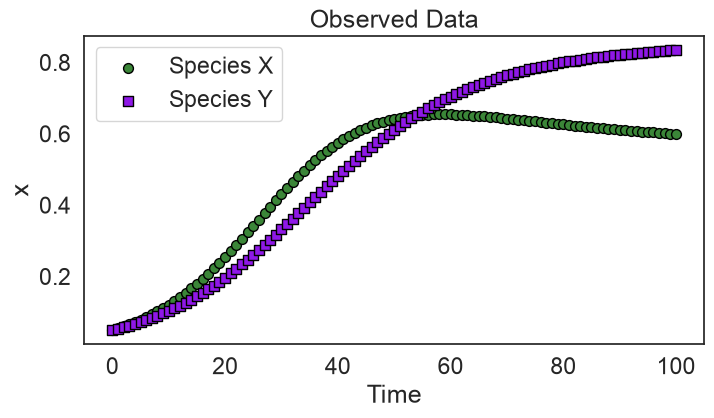

In [4]:
# Plot the dynamics of the two species over time
plt.figure(figsize=(8, 4))
sns.scatterplot(data=observations_df, x='t', y='x', label='Species X', 
                color=LV_PALETTE['x'], s=50, marker='o',
                edgecolor='black', linewidth=1, zorder=10)
sns.scatterplot(data=observations_df, x='t', y='y', label='Species Y', 
                color=LV_PALETTE['y'], s=50, marker='s',
                edgecolor='black', linewidth=1, zorder=10)
# sns.lineplot(data=observations_df, x='t', y='x', label='Species X', 
#              color='blue', linewidth=2, zorder=5)
# sns.lineplot(data=observations_df, x='t', y='y', label='Species Y', 
#              color='orange', linewidth=2, zorder=5)
plt.title('Observed Data')
plt.xlabel('Time')

#### 2) Setting up the SINDy problem

To apply SINDy, we need to define the following three components:
1. The **derivative matrix**, $\dot{\mathbf{\hat{X}}}$, which contains the estimated time derivatives of the state variables at each observation time.
2. The **library matrix**, $\mathbf{\Theta}(\mathbf{\hat{X}})$, which contains the evaluated candidate functions at each observation time.
3. The **sparsity threshold**, $\lambda$, in the STLS algorithm, which determines how strict we are in enforcing sparsity in the coefficient matrix.

Let's first obtain the derivatives:

In [5]:
# ------------------------------------------------------------------
# 1. Estimating the derivative matrix, $\dot{\mathbf{\hat{X}}}$
# ------------------------------------------------------------------
# For convenience, we will use the `np.gradient()` function from numpy which implements a 2nd-order 
# central difference method to compute the numerical derivative of a time series. Note that the accuracy of 
# the method we use will directly affect the accuracy of the SINDy model we learn!
X_dot_obs = np.gradient(observations_df[['x', 'y']], sampling_interval, axis=0)

# Let's look at the first 10 rows of the derivative matrix to see what it looks like:
X_dot_obs[:10, :]

array([[0.00482735, 0.00388337],
       [0.0050392 , 0.00402191],
       [0.00547742, 0.00430689],
       [0.00594485, 0.00460776],
       [0.00644175, 0.00492473],
       [0.006968  , 0.00525787],
       [0.00752304, 0.00560712],
       [0.00810583, 0.00597225],
       [0.00871472, 0.00635285],
       [0.00934742, 0.0067483 ]])

Next, we construct the library matrix. For this example, we will use a library of polynomial functions. That's a reasonable starting point here because many well-known models in ecology use polynomial terms to describe the interactions between species. In practice, choosing the right library is a key part of the SINDy workflow, and requires careful thought. The choice of library will depend on the system being studied and the goals of the analysis. 

In [6]:
# ------------------------------------------------------------------
# 2. Building the library matrix, $\mathbf{\Theta}(\mathbf{\hat{X}})$
# ------------------------------------------------------------------

n_observations = observations_df.shape[0]

# Add a column for the constant term (1)
theta = np.ones((n_observations, 1))

# Let's also create a list of the names of the library functions we have included to help us keep track of them:
library_function_names = ['1']

# Inspect the first 10 rows of the library matrix to see what it looks like:
theta[:10, ]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.]])

In [7]:
# Next, let's add the linear terms for each species (i.e. x and y):
theta = np.column_stack((
    theta,
    observations_df[['x', 'y']].values
))
library_function_names.extend(['x', 'y'])

theta[:10, ]

array([[1.        , 0.05      , 0.05      ],
       [1.        , 0.05482735, 0.05388337],
       [1.        , 0.0600784 , 0.05804383],
       [1.        , 0.06578218, 0.06249715],
       [1.        , 0.07196811, 0.06725935],
       [1.        , 0.07866568, 0.07234661],
       [1.        , 0.0859041 , 0.0777751 ],
       [1.        , 0.09371177, 0.08356085],
       [1.        , 0.10211576, 0.08971959],
       [1.        , 0.1111412 , 0.09626654]])

In [8]:
# Next, let's add the quadratic terms
theta = np.column_stack((
    theta,
    observations_df[['x', 'y']].values ** 2 # the x^2 and y^2 terms
))
theta = np.column_stack((
    theta,
    observations_df['x'].values * observations_df['y'].values  # the x y term
))
library_function_names.extend(['x^2', 'y^2', 'x y'])

# Inspect
theta[:10, ]

array([[1.        , 0.05      , 0.05      , 0.0025    , 0.0025    ,
        0.0025    ],
       [1.        , 0.05482735, 0.05388337, 0.00300604, 0.00290342,
        0.00295428],
       [1.        , 0.0600784 , 0.05804383, 0.00360941, 0.00336909,
        0.00348718],
       [1.        , 0.06578218, 0.06249715, 0.0043273 , 0.00390589,
        0.0041112 ],
       [1.        , 0.07196811, 0.06725935, 0.00517941, 0.00452382,
        0.00484053],
       [1.        , 0.07866568, 0.07234661, 0.00618829, 0.00523403,
        0.0056912 ],
       [1.        , 0.0859041 , 0.0777751 , 0.00737951, 0.00604897,
        0.0066812 ],
       [1.        , 0.09371177, 0.08356085, 0.0087819 , 0.00698242,
        0.00783063],
       [1.        , 0.10211576, 0.08971959, 0.01042763, 0.00804961,
        0.00916178],
       [1.        , 0.1111412 , 0.09626654, 0.01235237, 0.00926725,
        0.01069918]])

In [9]:
# Let's print the final shape of the library matrix and the names of the functions we have included in it:
print(f"Number of library functions: {theta.shape[1]}")
print(f"Library function names: {library_function_names}")
print(f"Number of observations: {theta.shape[0]}")
print(f"Final library matrix shape: {theta.shape}")

Number of library functions: 6
Library function names: ['1', 'x', 'y', 'x^2', 'y^2', 'x y']
Number of observations: 101
Final library matrix shape: (101, 6)


We are now ready to perform inference. To do so, we solve the following multi-variate, multiple, linear regression problem
\begin{equation}
    \dot{\mathbf{\hat{X}}} = \mathbf{\Theta}(\mathbf{\hat{X}})\,\boldsymbol{\Xi},
\end{equation}

for the coefficient matrix $\boldsymbol{\Xi}$, whose entries determine which candidate functions in the library contribute to each governing equation, and with what weight.

The key advantage of this formulation is that it reduces a problem of dynamical systems identification to one of linear regression — a well-studied problem for which robust, scalable solvers already exist. Let's ignore the need for sparsity for now and just use ordinary least squares (OLS) to solve the regression problem. We can do so in a one-liner:

In [20]:
# Solve for the coefficient matrix $\boldsymbol{\Xi}$ using ordinary least squares (OLS):
ols_results = np.linalg.lstsq(theta, X_dot_obs, rcond=None)

# Unpack the results of the OLS regression:
xi = ols_results[0] # The least-squares solution for the coefficient matrix
residuals = ols_results[1] # The residuals of the regression

print(f"Mean squared error of the regression: {residuals / n_observations}")
xi

Mean squared error of the regression: [3.01050989e-10 1.39753564e-10]


array([[ 1.41254156e-04,  8.99509074e-05],
       [ 1.02321687e-01,  1.67790339e-03],
       [-4.29652208e-03,  7.70487180e-02],
       [-9.98046328e-02, -1.57237358e-04],
       [ 3.66884222e-03, -7.75816838e-02],
       [-5.11574492e-02, -2.05228763e-02]])

Let's test how well the obtained solution matches the observed data:

In [21]:
def sindy_rhs(t, x, xi):
    """
    Compute the right-hand side of the SINDy model in a way that's compatible with scipy's ODE solvers.
    
    Parameters:
    - t: time (not used in this function, but included for compatibility with ODE solvers)
    - x: state vector (current values of the species)
    - xi: coefficient matrix (learned from regression)
    
    Returns:
    - dxdt: time derivative of the state vector
    """
    # Evaluate the library functions at the current state
    # theta_eval = np.array([1, x[0], x[1], x[0]**2, x[1]**2, x[0]*x[1], 
    #                        x[0]**3, x[1]**3, x[0]**2*x[1], x[0]*x[1]**2])
    theta_eval = np.array([1, x[0], x[1], x[0]**2, x[1]**2, x[0]*x[1]])
    
    # Compute the time derivative using the learned coefficients
    dxdt = theta_eval @ xi
    
    return dxdt

# Solve the SINDy model using the learned coefficients and compare it to the original Lotka-Volterra dynamics
t_span = (0, duration_of_experiment)
t_eval = observations_df['t'].values
x0 = observations_df[['x', 'y']].iloc[0].values  # initial conditions
solution = solve_ivp(
    fun=sindy_rhs,
    t_span=t_span,
    y0=x0,
    args=(xi,),
    t_eval=t_eval,
    method='LSODA',
    rtol=1e-12,
    atol=1e-12,
    max_step=0.1
)

# Re-format into a DataFrame for plotting
prediction_df_sindy = pd.DataFrame(solution.y.T, columns=['x', 'y'], index=t_eval)
prediction_df_sindy.reset_index(inplace=True)
prediction_df_sindy.rename(columns={'index': 't'}, inplace=True)
prediction_df_sindy.head()

,t,x,y
0,0,0.050000,0.050000
1,1,0.054877,0.053914
2,2,0.060176,0.058104
3,3,0.065928,0.062586
4,4,0.072162,0.067376


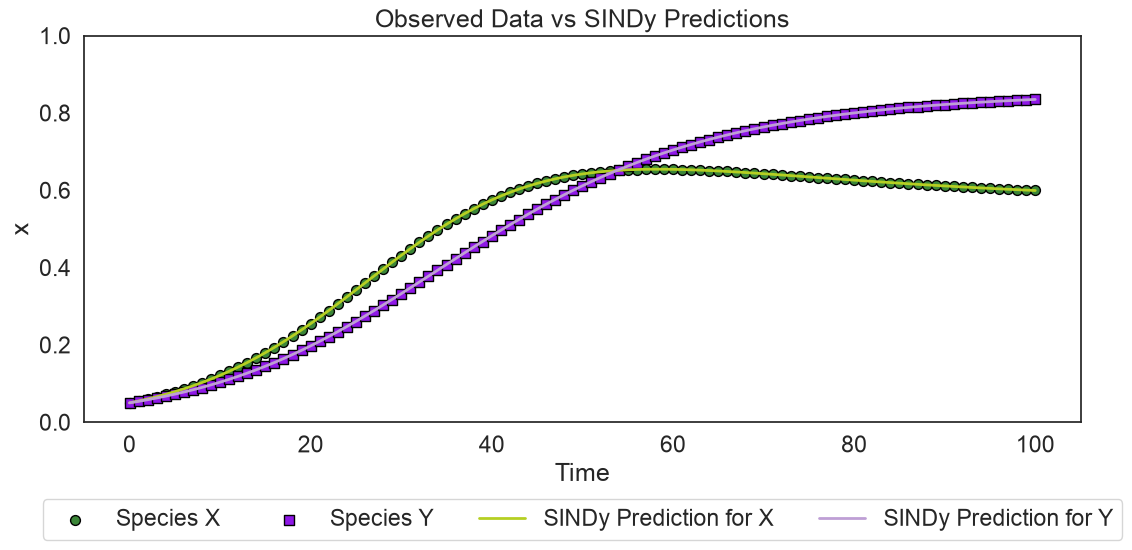

In [22]:
# Plot the predicted dynamics on top of the observed data
plt.figure(figsize=(12, 6))
sns.scatterplot(data=observations_df, x='t', y='x', label='Species X', 
                color=LV_PALETTE['x'], s=50, marker='o',
                edgecolor='black', linewidth=1, zorder=5)
sns.scatterplot(data=observations_df, x='t', y='y', label='Species Y', 
                color=LV_PALETTE['y'], s=50, marker='s',
                edgecolor='black', linewidth=1, zorder=5)
sns.lineplot(data=prediction_df_sindy, x='t', y='x', label='SINDy Prediction for X', 
             color=LV_PALETTE['x_sindy'], linewidth=2, zorder=10)
sns.lineplot(data=prediction_df_sindy, x='t', y='y', label='SINDy Prediction for Y', 
             color=LV_PALETTE['y_sindy'], linewidth=2, zorder=10)
plt.ylim(0, 1)
plt.title('Observed Data vs SINDy Predictions')
plt.xlabel('Time')
plt.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=4, borderaxespad=0)
plt.tight_layout()

The model fit is excellent! How about the inferred model structure? Let's take a look at the coefficient matrix:

In [23]:
# Turn the coefficient matrix into a pandas DataFrame for easier interpretation
xi_df = pd.DataFrame(xi, index=library_function_names, columns=['x_dot', 'y_dot'])
xi_df

,x_dot,y_dot
1,0.000141,0.000090
x,0.102322,0.001678
y,-0.004297,0.077049
x^2,-0.099805,-0.000157
y^2,0.003669,-0.077582
x y,-0.051157,-0.020523


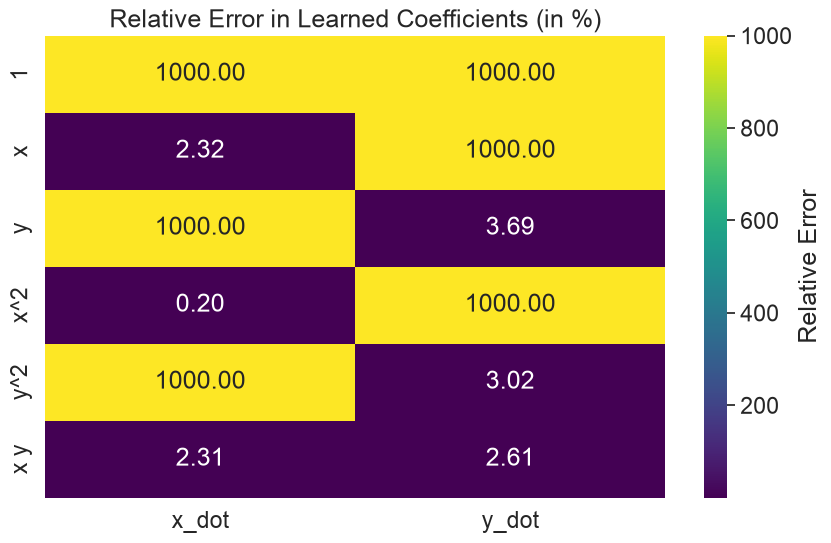

In [24]:
# To make it easy to assess the accuracy of the learned coefficients, let's 
# annotate the dataframe with the ground truth parameters. For reference, here are the equations again:
# dx/dt = r_x * x - c_xx * x^2 - c_yx * x * y
# dy/dt = r_y * y - c_yy * y^2 - c_xy * x * y
# Library order: ['1', 'x', 'y', 'x^2', 'y^2', 'x y', 'x^3', 'y^3', 'x^2 y', 'x y^2']
x_dot_true = [0, params_dict['r_x'], 0, -params_dict['c_xx'], 0, -params_dict['c_yx']]
y_dot_true = [0, 0, params_dict['r_y'], 0, -params_dict['c_yy'], -params_dict['c_xy']]
xi_df['x_dot_true'] = x_dot_true
xi_df['y_dot_true'] = y_dot_true

# Compute the relative error between the learned coefficients and the true coefficients
xi_df['x_dot_error'] = np.abs(xi_df['x_dot'] - xi_df['x_dot_true']) / (np.abs(xi_df['x_dot_true']) + 1e-12)
xi_df['y_dot_error'] = np.abs(xi_df['y_dot'] - xi_df['y_dot_true']) / (np.abs(xi_df['y_dot_true']) + 1e-12)
xi_df['x_dot_error'] = xi_df['x_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['y_dot_error'] = xi_df['y_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['x_dot_error'] = xi_df['x_dot_error'] * 100  # Convert to percentage
xi_df['y_dot_error'] = xi_df['y_dot_error'] * 100  # Convert to percentage

# Make a heatmap to visualise the error
plt.figure(figsize=(10, 6))
sns.heatmap(xi_df[['x_dot_error', 'y_dot_error']],
            annot=True, fmt=".2f", cmap="viridis", cbar_kws={'label': 'Relative Error'},
            xticklabels=['x_dot', 'y_dot'], yticklabels=library_function_names)
plt.title('Relative Error in Learned Coefficients (in %)');

We make two observations:
- For the terms that are part of the true governing equations, the learned coefficients are very close to the true values. This is a good sign, and suggests that we are on the right track in identifying the governing equations.
- However, we also see that the coefficient matrix is dense, with some weight given to all of the proposed candidate functions, including those terms which are not part of either of the true governing equations. This is not too surprising: by virtue of how we constructed the library matrix the columns are highly correlated. In addition, they have very different scales. Both are known issues for OLS regression, and why we need to enforce sparsity in the coefficient matrix. So, let's now move on to the last step and do this.

#### 3) Apply STLSQ to performe sparse regression

Let's apply the STLSQ algorithm to enforce sparsity in the coefficient matrix. We will use a threshold of $\lambda = 0.01$ for now, but we will explore the effect of this threshold on the results later.

In [25]:
from sklearn.linear_model import ridge_regression

def STLQ(theta, x_dot, threshold, n_iterations=10):
    n_states = x_dot.shape[1]  # Number of state variables (e.g., 2 for Lotka-Volterra)
    # Start by solving the least-squares problem to get an initial guess for the coefficient matrix
    xi = np.linalg.lstsq(theta, x_dot)[0]

    for _ in range(n_iterations): # Sequential thresholding
        small_coeffs = (np.abs(xi) < threshold) # Find small coefficients
        xi[small_coeffs] = 0 # and threshold
        
        for i in range(n_states):  # n_states is state dimension
            big_coeffs_idx = ~small_coeffs[:, i]
            # regress dynamics onto remaining terms to find sparse Xi
            xi[big_coeffs_idx, i] = np.linalg.lstsq(theta[:, big_coeffs_idx], x_dot[:, i])[0]
    return xi
    
# Perform sparse regression
threshold = 0.01 # this is the sparsification parameter: coefficients below this value are set to zero
xi = STLQ(theta, X_dot_obs, threshold, n_iterations=25)
xi


array([[ 0.        ,  0.        ],
       [ 0.09995375,  0.        ],
       [ 0.        ,  0.07999848],
       [-0.09992009,  0.        ],
       [ 0.        , -0.07996702],
       [-0.05000253, -0.02003553]])

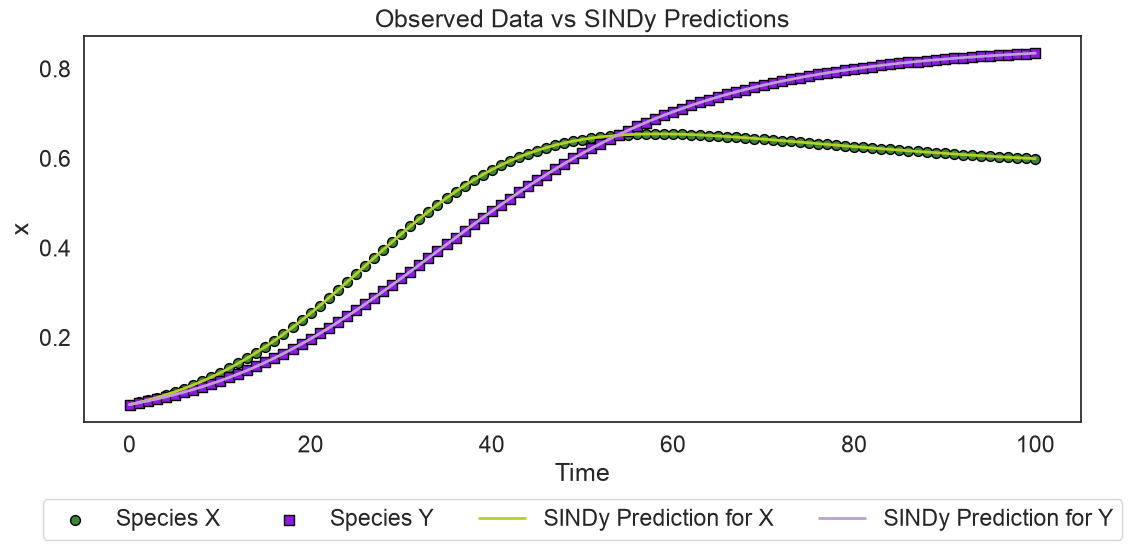

In [ ]:
# Let's examine our new solution
solution = solve_ivp(
    fun=sindy_rhs,
    t_span=t_span,
    y0=x0,
    args=(xi,),
    t_eval=t_eval,
)

# Re-format into a DataFrame for plotting
prediction_df_sindy = pd.DataFrame(solution.y.T, columns=['x', 'y'], index=t_eval)
prediction_df_sindy.reset_index(inplace=True)
prediction_df_sindy.rename(columns={'index': 't'}, inplace=True)

# Plot the predicted dynamics on top of the observed data
plt.figure(figsize=(12, 6))
sns.scatterplot(data=observations_df, x='t', y='x', label='Species X', 
                color=LV_PALETTE['x'], s=50, marker='o',
                edgecolor='black', linewidth=1, zorder=5)
sns.scatterplot(data=observations_df, x='t', y='y', label='Species Y', 
                color=LV_PALETTE['y'], s=50, marker='s',
                edgecolor='black', linewidth=1, zorder=5)
sns.lineplot(data=prediction_df_sindy, x='t', y='x', label='SINDy Prediction for X', 
             color=LV_PALETTE['x_sindy'], linewidth=2, zorder=10)
sns.lineplot(data=prediction_df_sindy, x='t', y='y', label='SINDy Prediction for Y', 
             color=LV_PALETTE['y_sindy'], linewidth=2, zorder=10)
plt.title('Observed Data vs SINDy Predictions')
plt.xlabel('Time')
plt.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=4, borderaxespad=0)
plt.tight_layout()

In [33]:
# Let's examine the new coefficient matrix:
xi_df = pd.DataFrame(xi, index=library_function_names, columns=['x_dot', 'y_dot'])
xi_df

,x_dot,y_dot
1,0.000000,0.000000
x,0.099954,0.000000
y,0.000000,0.079998
x^2,-0.099920,0.000000
y^2,0.000000,-0.079967
x y,-0.050003,-0.020036


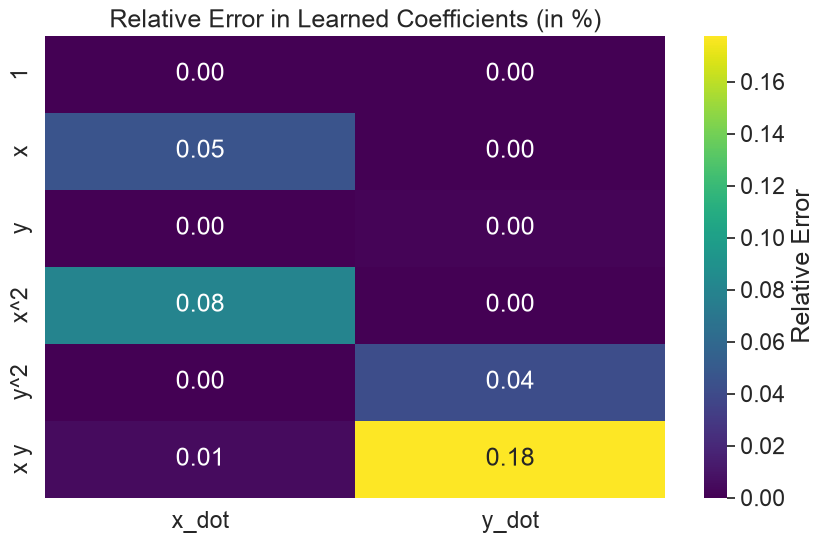

In [30]:
# Compute the relative error between the learned coefficients and the true coefficients
xi_df['x_dot_true'] = x_dot_true
xi_df['y_dot_true'] = y_dot_true
xi_df['x_dot_error'] = np.abs(xi_df['x_dot'] - xi_df['x_dot_true']) / (np.abs(xi_df['x_dot_true']) + 1e-12)
xi_df['y_dot_error'] = np.abs(xi_df['y_dot'] - xi_df['y_dot_true']) / (np.abs(xi_df['y_dot_true']) + 1e-12)
xi_df['x_dot_error'] = xi_df['x_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['y_dot_error'] = xi_df['y_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['x_dot_error'] = xi_df['x_dot_error'] * 100  # Convert to percentage
xi_df['y_dot_error'] = xi_df['y_dot_error'] * 100  # Convert to percentage

# Make a heatmap to visualise the error
plt.figure(figsize=(10, 6))
sns.heatmap(xi_df[['x_dot_error', 'y_dot_error']],
            annot=True, fmt=".2f", cmap="viridis", cbar_kws={'label': 'Relative Error'},
            xticklabels=['x_dot', 'y_dot'], yticklabels=library_function_names)
plt.title('Relative Error in Learned Coefficients (in %)');

In [31]:
# Let's write out the final equations:
for i, state in enumerate(['x', 'y']):
    equation_terms = []
    for j, func in enumerate(library_function_names):
        coeff = xi[j, i]
        if np.abs(coeff) > 0:
            equation_terms.append(f"{coeff:.5f} * {func}")
    equation_str = " + ".join(equation_terms)
    print(f"d{state}/dt = {equation_str}")

dx/dt = 0.09995 * x + -0.09992 * x^2 + -0.05000 * x y
dy/dt = 0.08000 * y + -0.07997 * y^2 + -0.02004 * x y


In [32]:
# In comparison, here are the ground truth equations:
for i, state in enumerate(['x', 'y']):
    equation_terms = []
    for j, func in enumerate(library_function_names):
        coeff = x_dot_true[j] if state == 'x' else y_dot_true[j]
        if np.abs(coeff) > 0:
            equation_terms.append(f"{coeff:.5f} * {func}")
    equation_str = " + ".join(equation_terms)
    print(f"d{state}/dt = {equation_str}")

dx/dt = 0.10000 * x + -0.10000 * x^2 + -0.05000 * x y
dy/dt = 0.08000 * y + -0.08000 * y^2 + -0.02000 * x y


In short: success!

## pySINDy

The `pysindy` package offers a set of useful tools for applying SINDy to data. It provides a simple interface for defining the library of candidate functions, estimating derivatives, and solving the sparse regression problem. For example, we can perform the same analysis as above using `pysindy` with just a few lines of code:

In [268]:
import pysindy as ps

# 1) Choose the differentiation method
differentiation_method = ps.FiniteDifference(order=2) # central difference 2nd order

# 2) Choose library
feature_library = ps.PolynomialLibrary(degree=2) # polynomial library up to degree 2

# 3) Select optimiser
optimiser = ps.STLSQ(threshold=0.01, alpha=0) # sequential thresholded least squares

# 4) Instantiate and fit the SINDy model
model = ps.SINDy(optimizer = optimiser, 
                 differentiation_method = differentiation_method,
                 feature_library=feature_library)
model.fit(observations_df[["x", "y"]].values, t=observations_df["t"].values, feature_names=["x", "y"])

# Print the learned model
model.print()

(x)' =  0.100 x + -0.100 x^2 + -0.050 x y
(y)' =  0.080 y + -0.020 x y + -0.080 y^2


In [269]:
# Simulate the model
x_predicted_sindy = model.simulate(x0 = x0,  # initial conditions
               t = t_eval # time points at which to evaluate the solution
           )

# Re-format into a DataFrame for plotting
prediction_df_pysindy = pd.DataFrame(x_predicted_sindy, columns=['x', 'y'], index=t_eval)
prediction_df_pysindy.reset_index(inplace=True)
prediction_df_pysindy.rename(columns={'index': 't'}, inplace=True)
prediction_df_pysindy.head()

,t,x,y
0,0,0.050000,0.050000
1,1,0.054824,0.053882
2,2,0.060071,0.058041
3,3,0.065771,0.062493
4,4,0.071952,0.067254


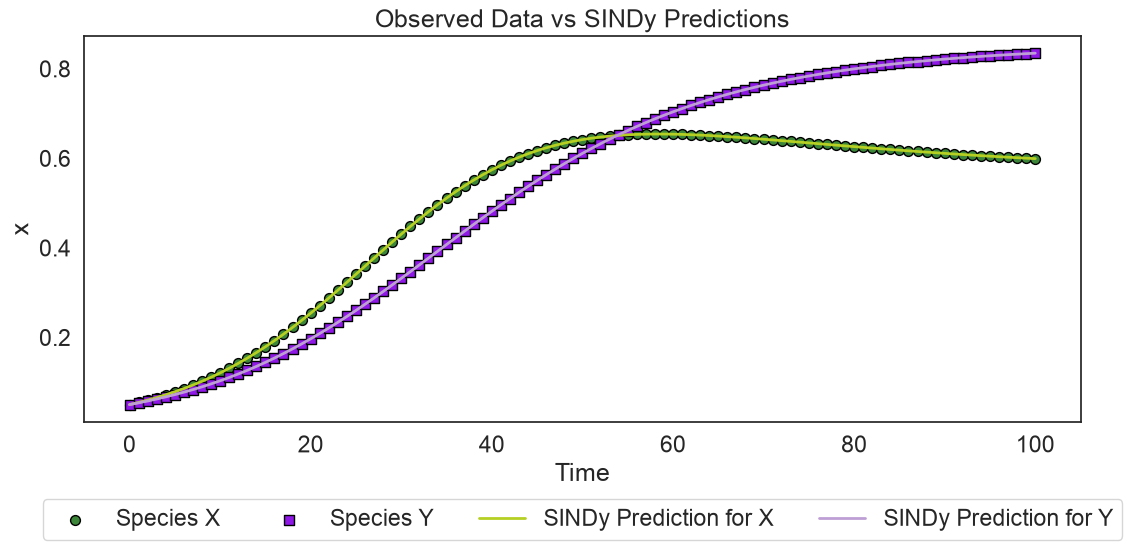

In [270]:
# Plot the predicted dynamics on top of the observed data
plt.figure(figsize=(12, 6))
sns.scatterplot(data=observations_df, x='t', y='x', label='Species X', 
                color=LV_PALETTE['x'], s=50, marker='o',
                edgecolor='black', linewidth=1, zorder=5)
sns.scatterplot(data=observations_df, x='t', y='y', label='Species Y', 
                color=LV_PALETTE['y'], s=50, marker='s',
                edgecolor='black', linewidth=1, zorder=5)
sns.lineplot(data=prediction_df_pysindy, x='t', y='x', label='SINDy Prediction for X', 
             color=LV_PALETTE['x_sindy'], linewidth=2, zorder=10)
sns.lineplot(data=prediction_df_pysindy, x='t', y='y', label='SINDy Prediction for Y', 
             color=LV_PALETTE['y_sindy'], linewidth=2, zorder=10)
plt.title('Observed Data vs SINDy Predictions')
plt.xlabel('Time')
plt.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=4, borderaxespad=0)
plt.tight_layout()

In addition, `pysindy` provides a number of useful features, including:

In [271]:
# A handy interface for inspecting models
model

,optimizer,"STLSQ(alpha=0, threshold=0.01)"
,feature_library,PolynomialLibrary()
,differentiation_method,FiniteDifference()
Name,Type,Value
n_control_features_,int,0
n_features_in_,int,2
n_output_features_,int,6
,degree,2
,include_interaction,True
,interaction_only,False
,include_bias,True


In [272]:
# Similarly for the feature library
feature_library

PolynomialLibrary()

In [273]:
# Accessing the feature names
model.get_feature_names()

['1', 'x', 'y', 'x^2', 'x y', 'y^2']

In [274]:
# Accessing the learned equations
model.print()

(x)' =  0.100 x + -0.100 x^2 + -0.050 x y
(y)' =  0.080 y + -0.020 x y + -0.080 y^2


In [275]:
# Accessing the learned coefficients
model.coefficients()

array([[ 0.        ,  0.09993582,  0.        , -0.09988785, -0.05000474,
         0.        ],
       [ 0.        ,  0.        ,  0.07997728,  0.        , -0.01998985,
        -0.07997757]])

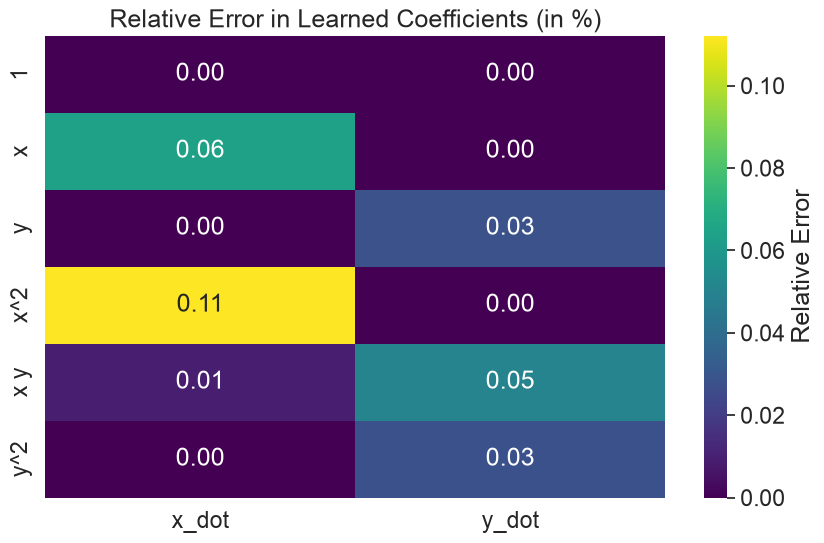

In [276]:
# We can use that to make the coefficient heatmap:
xi_df = pd.DataFrame(model.coefficients().T, index=model.get_feature_names(), columns=['x_dot', 'y_dot'])
xi_df['x_dot_true'] = [0, params_dict['r_x'], 0, -params_dict['c_xx'], -params_dict['c_yx'], 0]
xi_df['y_dot_true'] = [0, 0, params_dict['r_y'], 0, -params_dict['c_xy'], -params_dict['c_yy']]
xi_df['x_dot_error'] = np.abs(xi_df['x_dot'] - xi_df['x_dot_true']) / (np.abs(xi_df['x_dot_true']) + 1e-12)
xi_df['y_dot_error'] = np.abs(xi_df['y_dot'] - xi_df['y_dot_true']) / (np.abs(xi_df['y_dot_true']) + 1e-12)
xi_df['x_dot_error'] = xi_df['x_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['y_dot_error'] = xi_df['y_dot_error'].clip(lower=0, upper=10) # Clip for visualization purposes
xi_df['x_dot_error'] = xi_df['x_dot_error'] * 100  # Convert to percentage
xi_df['y_dot_error'] = xi_df['y_dot_error'] * 100  # Convert to percentage

# Make a heatmap to visualise the error
plt.figure(figsize=(10, 6))
sns.heatmap(xi_df[['x_dot_error', 'y_dot_error']],
            annot=True, fmt=".2f", cmap="viridis", cbar_kws={'label': 'Relative Error'},
            xticklabels=['x_dot', 'y_dot'], yticklabels=model.get_feature_names())
plt.title('Relative Error in Learned Coefficients (in %)');

In [277]:
xi_df

,x_dot,y_dot,x_dot_true,y_dot_true,x_dot_error,y_dot_error
1,0.000000,0.000000,0.00,0.00,0.000000,0.000000
x,0.099936,0.000000,0.10,0.00,0.064175,0.000000
y,0.000000,0.079977,0.00,0.08,0.000000,0.028404
x^2,-0.099888,0.000000,-0.10,0.00,0.112148,0.000000
x y,-0.050005,-0.019990,-0.05,-0.02,0.009472,0.050734
y^2,0.000000,-0.079978,0.00,-0.08,0.000000,0.028034


For more information and tutorials on using `pysindy`, see the [pysindy documentation](https://pysindy.readthedocs.io/en/latest/examples/index.html#id3).

## Scratch

To illustrate how SINDy works in practice, we will apply it to the Lotka-Volterra model, which is one of the most well-known models in ecology. It describes the dynamics of interactions between two species of organisms in an ecosystem. Let $x(t)$ denote the population of prey, and $y(t)$ denote the population of predators. The Lotka-Volterra equations are given by
$$
\begin{align}
\dot{x} &= r_x (1-x) x - c_{yx} x y \\
\dot{y} &= r_y (1-y) y - c_{xy} y x \\
\end{align}
$$





$$
\begin{align}
\dot{x} &= \sigma(y-x) = \sigma y + (-\sigma) x \\
\dot{y} &= x(\rho-z)-y = \rho y + (-1) y + (-1) x z \\
\dot{z} &= xy - \beta z = (-\beta) z + 1 x y
\end{align}
$$


\begin{align}
\dot{x} &= \sigma(y-x) = \sigma y + (-\sigma) x \\
\dot{y} &= x(\rho-z)-y = \rho y + (-1) y + (-1) x z \\
\dot{z} &= xy - \beta z = (-\beta) z + 1 x y
\end{align}
$$

\begin{equation}
    \begin{bmatrix} \dot{x} \\ \dot{y} \\ \dot{z} \end{bmatrix}
    =
    \begin{bmatrix}
        -\sigma & \sigma & 0      & 0  & 0 \\
        \rho    & -1     & 0      & -1 & 0 \\
        0       & 0      & -\beta & 0  & 1
    \end{bmatrix}
    \begin{bmatrix} x \\ y \\ z \\ xz \\ xy \end{bmatrix}
\end{equation}

Each equation is linear in its parameters $(\sigma, \rho, \beta)$, even though the terms $xz$ and $xy$ are nonlinear in the state. We can make this explicit by collecting all state-variable terms appearing on the RHS into a \textbf{function library}:

\begin{equation}
    \boldsymbol{\Theta}(\mathbf{x}) = \begin{bmatrix} 1 & x & y & z & xy & xz & yz & x^2 & \cdots \end{bmatrix}
\end{equation}

and reading off the coefficients of each term into a \textbf{coefficient matrix} $\boldsymbol{\Xi}$:

\begin{equation}
    \dot{\mathbf{x}}^\top = \boldsymbol{\Theta}(\mathbf{x})\,\boldsymbol{\Xi}
    \;=\;
    \begin{bmatrix} 1 & x & y & z & xy & xz & \cdots \end{bmatrix}
    \begin{bmatrix}
        0      & 0  & 0      \\
        -\sigma & \rho & 0   \\
        \sigma  & -1   & 0   \\
        0      & 0  & -\beta \\
        0      & 0  & 1      \\
        0      & -1 & 0      \\
        \vdots & \vdots & \vdots
    \end{bmatrix}
\end{equation}

The columns of $\boldsymbol{\Xi}$ correspond to $\dot{x}$, $\dot{y}$, $\dot{z}$, and the rows to the library terms. Most entries are zero---the Lorenz system activates only 6 out of potentially many candidate terms. This \textbf{sparsity} is exactly what SINDy exploits to recover governing equations from data.



\begin{equation}
    \dot{\mathbf{x}}^\top = \boldsymbol{\Theta}(\mathbf{x})\,\boldsymbol{\Xi}
    \;=\;
    \begin{bmatrix} 1 & x & y & z & xy & xz & \cdots \end{bmatrix}
    \begin{bmatrix}
        0      & 0  & 0      \\
        -\sigma & \rho & 0   \\
        \sigma  & -1   & 0   \\
        0      & 0  & -\beta \\
        0      & 0  & 1      \\
        0      & -1 & 0      \\
        \vdots & \vdots & \vdots
    \end{bmatrix}
\end{equation}

So, while each RHS is non-linear in x xxx, and the dynamics of the system are highly non-linear, when we view the RHS from the perspective of the coefficients in front of each functional of x xxx, they are simply weighted sums - where the terms we are summing are the coefficients and the weights are the functional terms in x xxx.

More formally, if we have a dynamical system with $k$ state variables, x_i(t) for $i=1,...,k$, SINDy assumes that its time-evolution is governed by a system of differential equations of the form
xxx
, where xxx is a matrix of functions involving the state variables x (called the "library matrix"), and xxx is a matrix of coefficients, detailing how these functions are to be added together to generate the governing equations (one column for each state variable). 


$$
\begin{align}
\dot{x} &= r_x (1-x) x - c_{yx} x y = x r_x - x^2 r_x - x y c_{yx} \\
\dot{y} &= r_y (1-y) y - c_{xy} y x = y r_y - y^2 r_y - x y c_{xy} \\
\end{align}
$$
= (1 x y x^2 y^2 xy) ((0, r_x, 0, r_x, 0, -c_{yx}), (0, 0, r_y, 0, r_y, -c_{xy}))

 x^3 y^3 x^2y xy^2 y^3



let us assume we observe a system at k time points, t_i for i from 0 to k, so that we have a matrix of observation x = [(x_0(), x_1, x_)], where we have one observation for each state variable $x_i$, for $i = 1, ..., n$. 

The key idea of SINDy is to cast the problem of discovering the underlying dynamics of a system as a **linear and sparse** regression problem involving the system's derivatives. To illustrate what I mean by that, let us assume we observe a system at k time points, t_i for i from 0 to k, so that we have a matrix of observation x = [(x_0(), x_1, x_)], where we have one observation for each state variable $x_i$, for $i = 1, ..., n$. 

What this means is that if we have a system with $n$ state variable, $x_i$ for $i = 1, ..., n$, then SINDy assumes that its governing equations are given by:



, where xxx is a matrix of functions involving the state variables x, and xxx is a vector of parameters, detailing how these functions are to be added together to generate the governing equation. 

To illustrate what I mean by this, let us consider a simple Lotka-Volterra 

What this means is it that SINDy assumes that the governing equations we are trying to discover



The key assumption is that the governing (differential) equations are linear in their coefficents.

Key concepts:
- Fit to derivatives instead of observed time series. -> no forward simulation
- Cast inference as linear regression problem: linear in parameters
- Use sparse regression to avoid overfitting and identiy key terms driving the dynamics


It works with the derivatives. This means it never has to run a forward simulation of the system, which makes it computationally very efficient. However, this also means that it is sensitive to noise in the data, since numerical differentiation amplifies noise.

Key assumptions of SINDy:
- **Linearity:** The right-hand side of the ODEs can be expressed as a linear combination of a set of candidate functions (the "library")
- **Normal Errors:** Errors are normally distributed and independent. A common assumption, but this may not always be the case, in particular in biological systems - for example, populations cannot be negative.
<!-- ÷- The candidate functions in the library are chosen to be representative of the possible nonlinearities in the system. -->
<!-- - The system can be described by a set of ordinary differential equations (ODEs) -->
<!-- - The system is sparse, meaning that only a small number of terms in the library are needed to describe the dynamics of the system. -->

### Example application on a simple ecological model (the Lotka-Volterra competition model)

### Evaluating the model

#### Goodness-of-fit

#### Model Complexity

##### Model structure

## pySINDy

## Tuning the sparsity parameter, $\lambda$

### AIC-based model selection

### Stability selection

## Extensions

### SINDy with control

### Choice of the library

### Noisy/Sparse data

### Unobserved state variables

## Further Reading

## Acknowledgements